In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from scipy import stats
pd.set_option('display.max_columns',None)


In [2]:
#scaling, normalization
from sklearn.preprocessing import StandardScaler, MinMaxScaler

#kmeans, dbscan, hierarchical (sklearn)
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering 
#evaluation
from sklearn.metrics import silhouette_score
#import dataset
from sklearn.datasets import load_iris

#distance matrix (dbscan elbow, hierarchical)
from scipy.spatial.distance import pdist, squareform

# hierarchical (scipy)
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

In [3]:
car_data = pd.read_csv(r"C:\Users\X390\Desktop\UNI\Data Mining\dataset progetto\seller_info_dm1_2627.csv")


In [4]:
killcolumns = ['dominant_transmission','dominant_fuel_type','pct_salvage','pct_theft_title','dominant_wheel_system']
c_d_clean = car_data.drop(killcolumns,axis=1)

In [5]:
def iqr(sr: pd.Series):
    Q1 = sr.quantile(0.25)
    Q3 = sr.quantile(0.75)
    return (Q3-Q1)

def upper(sr: pd.Series):
    upperlimit = sr.quantile(0.75)+(1.5*iqr(sr))
    return upperlimit


def lower(sr: pd.Series):
    lowerlimit = sr.quantile(0.25)-(1.5*iqr(sr))
    return lowerlimit


In [8]:
pricebyseller = pd.DataFrame(car_data.loc[:,['seller_rating_class','price_median','mileage_median']])
pricebyseller

,seller_rating_class,price_median,mileage_median
0,medium,6700.0,193193.5
1,medium,10995.0,87589.0
2,low,7645.0,151434.0
3,medium,23449.0,31186.0
4,medium,8990.0,144471.5
...,...,...,...
13838,high,42625.0,12.0
13839,medium,31590.0,8.0
13840,medium,29992.5,9.0
13841,medium,32864.0,15.0


In [9]:
r_p_clean = pricebyseller[pricebyseller['price_median'] <=upper(pricebyseller['price_median'])]
r_p_clean

,seller_rating_class,price_median,mileage_median
0,medium,6700.0,193193.5
1,medium,10995.0,87589.0
2,low,7645.0,151434.0
3,medium,23449.0,31186.0
4,medium,8990.0,144471.5
...,...,...,...
13838,high,42625.0,12.0
13839,medium,31590.0,8.0
13840,medium,29992.5,9.0
13841,medium,32864.0,15.0


<Axes: xlabel='price_median', ylabel='mileage_median'>

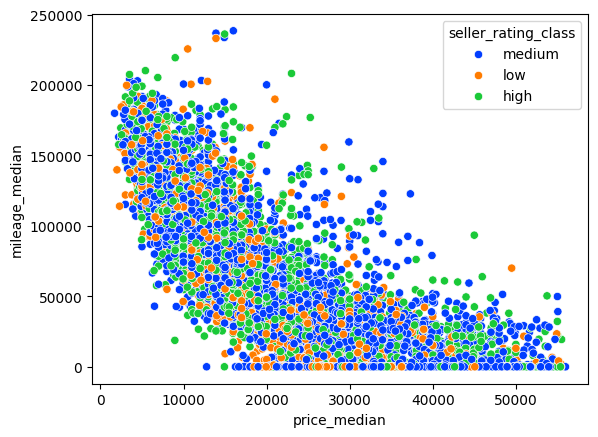

In [10]:
marks= list(r_p_clean['seller_rating_class'].unique())
sns.scatterplot(data=r_p_clean, x="price_median", y="mileage_median", hue='seller_rating_class', palette="bright")

In [11]:
x = r_p_clean.drop('seller_rating_class',axis=1).dropna().reset_index(drop=True)
scaler = StandardScaler()
scaler.fit(x)
X_scal = scaler.transform(x)



In [12]:
kmeans = KMeans(n_clusters=6,n_init=10,max_iter=100, random_state=94)
kmeans.fit(X_scal)

,n_clusters,6
,init,'k-means++'
,n_init,10
,max_iter,100
,tol,0.0001
,verbose,0
,random_state,94
,copy_x,True
,algorithm,'lloyd'


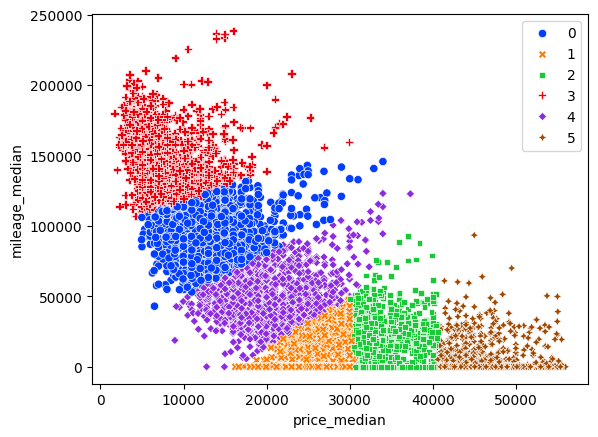

In [14]:
sns.scatterplot(data=x,
                x="price_median",
                y="mileage_median",
                hue=kmeans.labels_,
                style=kmeans.labels_,
                palette="bright")
plt.show()

In [15]:
kmeans.cluster_centers_

array([[-0.86273447,  0.8327583 ],
       [ 0.35279063, -0.85701469],
       [ 1.08383336, -0.81462021],
       [-1.2637121 ,  1.68960242],
       [-0.17170042, -0.17454933],
       [ 2.0783956 , -0.89344387]])

In [16]:
centers = scaler.inverse_transform(kmeans.cluster_centers_)
centers

array([[ 12425.19097736,  95249.48616601],
       [ 26309.97549896,   7521.3039798 ],
       [ 34660.58119516,   9722.30433686],
       [  7844.87584054, 139734.38304515],
       [ 20318.78267938,  42952.95428454],
       [ 46021.33579154,   5630.00491642]])

In [17]:
r_p_clean

,seller_rating_class,price_median,mileage_median
0,medium,6700.0,193193.5
1,medium,10995.0,87589.0
2,low,7645.0,151434.0
3,medium,23449.0,31186.0
4,medium,8990.0,144471.5
...,...,...,...
13838,high,42625.0,12.0
13839,medium,31590.0,8.0
13840,medium,29992.5,9.0
13841,medium,32864.0,15.0


In [18]:

r_p_clean = r_p_clean.dropna(axis=0).reset_index(drop=True)

r_p_clean

,seller_rating_class,price_median,mileage_median
0,medium,6700.0,193193.5
1,medium,10995.0,87589.0
2,low,7645.0,151434.0
3,medium,23449.0,31186.0
4,medium,8990.0,144471.5
...,...,...,...
13666,high,42625.0,12.0
13667,medium,31590.0,8.0
13668,medium,29992.5,9.0
13669,medium,32864.0,15.0


In [19]:
r_p_clean['kmeans_labels'] = kmeans.labels_
r_p_clean['kmeans_labels'] = r_p_clean['kmeans_labels'].map({0:"A",1:"B",2:"C",3:"D",4:"E",5:"F"})

r_p_clean

,seller_rating_class,price_median,mileage_median,kmeans_labels
0,medium,6700.0,193193.5,D
1,medium,10995.0,87589.0,A
2,low,7645.0,151434.0,D
3,medium,23449.0,31186.0,E
4,medium,8990.0,144471.5,D
...,...,...,...,...
13666,high,42625.0,12.0,F
13667,medium,31590.0,8.0,C
13668,medium,29992.5,9.0,B
13669,medium,32864.0,15.0,C


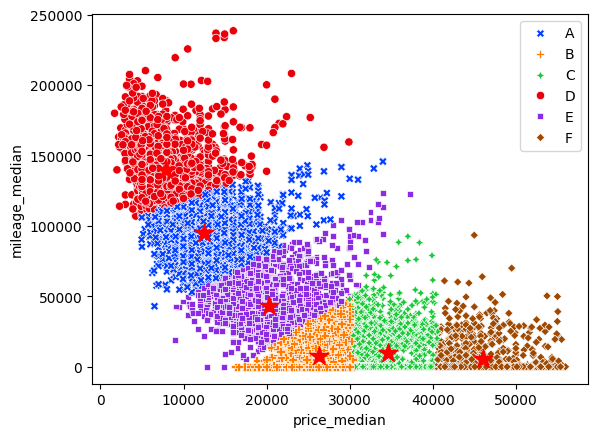

In [20]:
sns.scatterplot(data=r_p_clean, 
                x="price_median",
                y="mileage_median",
                hue='kmeans_labels', 
                style='kmeans_labels',
                palette="bright", 
                hue_order=["A", "B", "C","D","E","F"]
               )
plt.legend()
plt.scatter(centers[:,0], centers[:,1], c='red', marker='*', s=200)
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

df_sampled, _ =train_test_split(r_p_clean,test_size=0.75,stratify=r_p_clean['kmeans_labels'],random_state=42)

df_sampled    

,seller_rating_class,price_median,mileage_median,kmeans_labels
9865,high,5995.0,129802.0,D
13080,medium,28181.0,11.0,B
2380,high,3500.0,167535.0,D
9087,medium,14250.0,74839.0,A
941,medium,15235.0,85460.5,A
...,...,...,...,...
10717,high,7499.0,80035.0,A
9535,medium,16740.0,70977.0,A
7310,low,7950.0,107168.0,A
4462,medium,13450.0,106454.0,A


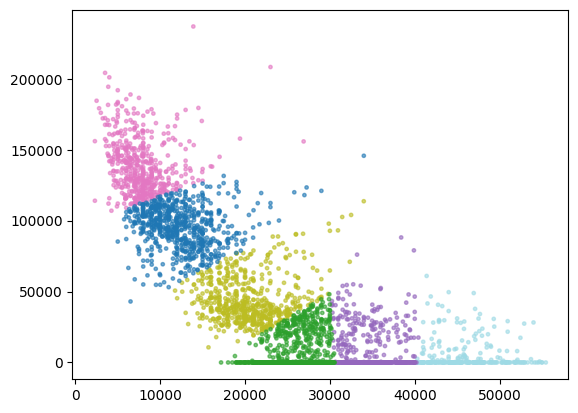

In [40]:
lab = df_sampled['kmeans_labels'].astype('category').cat.codes

plt.scatter(df_sampled['price_median'], df_sampled['mileage_median'],
            c=lab, s=6, alpha=0.6, cmap='tab20')
plt.show()



In [53]:
sample_scaled = scaler.transform(df_sampled.loc[ : ,'price_median':'mileage_median'].reset_index(drop=True))

sample_scaled

array([[-1.42565703,  1.4982902 ],
       [ 0.516587  , -1.00167412],
       [-1.64407851,  2.22508292],
       ...,
       [-1.25450914,  1.06232629],
       [-0.77301892,  1.04857361],
       [-0.98758847,  0.96826294]], shape=(3417, 2))

In [54]:
def get_linkage_matrix(model):
    # Create linkage matrix 
    
    # create the counts of samples under each node
    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1  # leaf node
            else:
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count

    linkage_matrix = np.column_stack(
        [model.children_, model.distances_, counts]
    ).astype(float)

    return linkage_matrix

def plot_dendrogram(model, **kwargs):
    linkage_matrix = get_linkage_matrix(model)
    dendrogram(linkage_matrix, **kwargs)

In [57]:
from scipy.cluster.hierarchy import linkage, dendrogram

Z = linkage(sample_scaled,method="ward")

Z

array([[1.60100000e+03, 2.40600000e+03, 1.92614613e-05, 2.00000000e+00],
       [2.67000000e+02, 3.24000000e+02, 1.92614613e-05, 2.00000000e+00],
       [4.16000000e+02, 3.00000000e+03, 3.85229226e-05, 2.00000000e+00],
       ...,
       [6.82600000e+03, 6.82700000e+03, 3.19477764e+01, 1.65800000e+03],
       [6.82800000e+03, 6.82900000e+03, 4.44608396e+01, 1.75900000e+03],
       [6.83000000e+03, 6.83100000e+03, 9.38884794e+01, 3.41700000e+03]],
      shape=(3416, 4))

In [59]:
model = AgglomerativeClustering(distance_threshold=0, n_clusters=None, 
                                metric='euclidean', linkage='complete')
model = model.fit(sample_scaled)

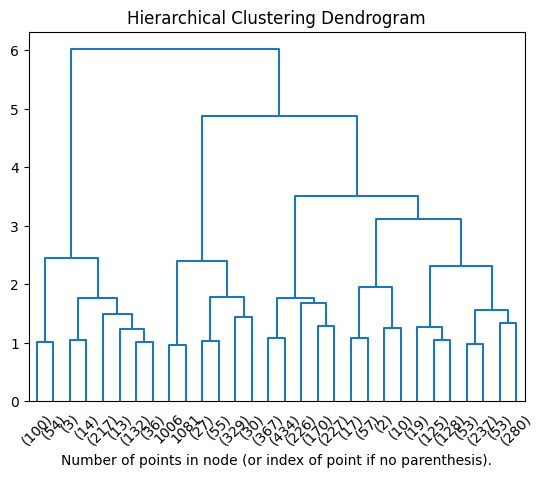

In [60]:
plt.title("Hierarchical Clustering Dendrogram")
plot_dendrogram(model, truncate_mode='lastp', color_threshold=0.7)
plt.xlabel("Number of points in node (or index of point if no parenthesis).")
plt.show()

In [61]:
Z= get_linkage_matrix(model)

labels = fcluster(Z,t=0.7,criterion='distance')

In [62]:
labels

array([19, 23, 16, ..., 42, 46, 42], shape=(3417,), dtype=int32)

In [63]:
print(silhouette_score(sample_scaled,labels))

0.29612518929273896


In [64]:
dist = pdist(sample_scaled,'euclidean')
dist = squareform(dist)

In [65]:
hier = AgglomerativeClustering(n_clusters=3, metric='precomputed', linkage='complete')
hier.fit(dist)

,n_clusters,3
,metric,'precomputed'
,memory,None
,connectivity,None
,compute_full_tree,'auto'
,linkage,'complete'
,distance_threshold,None
,compute_distances,False


In [70]:
shape = len(sample_scaled)
ideal_sim = np.eye(shape)

for i in range(shape):
    for j in range(0, i+1):
        ideal_sim[j][i] = 1 if hier.labels_[i] == hier.labels_[j] else 0

ideal_sim = ideal_sim + ideal_sim.T - np.diag(np.diag(ideal_sim)) # copying upper triangle in lower triangle

ideal_sim

array([[1., 0., 1., ..., 0., 0., 0.],
       [0., 1., 0., ..., 1., 1., 1.],
       [1., 0., 1., ..., 0., 0., 0.],
       ...,
       [0., 1., 0., ..., 1., 1., 1.],
       [0., 1., 0., ..., 1., 1., 1.],
       [0., 1., 0., ..., 1., 1., 1.]], shape=(3417, 3417))

In [73]:
sim = np.corrcoef(dist, ideal_sim)
sns.heatmap(sim, cmap="jet", annot=False)
plt.show()

MemoryError: Unable to allocate 178. MiB for an array with shape (6834, 3417) and data type float64